In [10]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import optuna
import sys
from pathlib import Path
import torch # Torch needs to be installed manually if you want cuda. See installation command on pytorch website
import warnings

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 10                             # optuna trials
N_ESTIMATORS = 2000                      # max boosting rounds per trial
EARLY_STOPPING_ROUNDS = 100
ES_FRACTION = 0.1                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # time series cross validation folds
DEBUG = True                             # print MdAPE and MAPE for every fold

In [12]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [13]:
from baseline_features import off_market_features, list_aware_features

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

X_train = make_features(train)
X_val = make_features(val)

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])

print(f"Features: {X_train.columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

Features: ['house_area_was_range', 'square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'lot_missing', 'latitude', 'longitude', 'municipality', 'community', 'house_type', 'house_style', 'month', 'year', 'day', 'is_apartment']
train: 139,931 sales up to 2025-12-01
val:   10,069 sales from 2025-12-01


In [14]:
# TODO: Try different losses
def mdape(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

loss = mdape

In [15]:
from sklearn.model_selection import TimeSeriesSplit


def cross_val(X, y, params, K=5, debug=False, validation_loss=mdape):
    """Walk-forward K-fold: each fold trains on every row before its validation block.
    X and y must be sorted by time (listings is sorted by date_sold).
    Early stopping uses the latest ES_FRACTION of each fold's training rows, never the
    validation block, so the fold scores are honest.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    mdape_scores = []
    mape_scores = []
    rounds = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(X), start=1):
        n_fit = int(len(train_idx) * (1 - ES_FRACTION))
        fit_idx, es_idx = train_idx[:n_fit], train_idx[n_fit:]
        X_fit, X_es, X_va = X.iloc[fit_idx], X.iloc[es_idx], X.iloc[val_idx]
        y_fit, y_es, y_va = y.iloc[fit_idx], y.iloc[es_idx], y.iloc[val_idx]

        model = XGBRegressor(**params, device=DEVICE, n_estimators=N_ESTIMATORS,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS, random_state=SEED)
        model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
        rounds.append(model.best_iteration + 1)
        pred = model.predict(X_va)
        mdape_scores.append(validation_loss(y_va, pred))

        mape_scores.append(np.mean(100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)))

        if debug:
            error = 100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)
            print(f"fold {fold}: train {len(fit_idx):,}  early stop {len(es_idx):,}  val {len(val_idx):,}  "
                  f"rounds {rounds[-1]}  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores), int(np.mean(rounds))

In [16]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 2048),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 0.1, step=0.01),
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 1, 10),
        "enable_categorical": True,
    }
    score, n_rounds = cross_val(X_train, y_train, params, K=K_FOLDS, debug=DEBUG, validation_loss=loss)
    trial.set_user_attr("n_rounds", n_rounds)
    return score

In [17]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!")
study.optimize(objective, n_trials=N_TRIALS)

print("best CV MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)
print("boosting rounds:", study.best_trial.user_attrs["n_rounds"])

[I 2026-10-16 17:21:54,089] A new study created in memory with name: VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 1220  MdAPE 11.01%  MAPE 13.32%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 1954  MdAPE 11.26%  MAPE 13.88%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 936  MdAPE 10.17%  MAPE 12.71%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 1187  MdAPE 10.38%  MAPE 13.32%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 749  MdAPE 11.49%  MAPE 14.59%
mean MdAPE 10.86%  mean MAPE 13.56%


[I 2026-10-16 17:22:09,308] Trial 0 finished with value: 10.863525366361246 and parameters: {'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.9, 'colsample_bytree': 0.5, 'max_bin': 1778, 'min_child_weight': 10, 'gamma': 0.1, 'lambda': 7.103714746188992, 'alpha': 0.0013187949354214168, 'max_delta_step': 1}. Best is trial 0 with value: 10.863525366361246.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 582  MdAPE 11.24%  MAPE 13.52%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 1057  MdAPE 11.38%  MAPE 14.33%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 749  MdAPE 10.74%  MAPE 13.28%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 1092  MdAPE 10.82%  MAPE 13.80%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 1245  MdAPE 11.62%  MAPE 14.85%
mean MdAPE 11.16%  mean MAPE 13.96%


[I 2026-10-16 17:22:16,103] Trial 1 finished with value: 11.157485222514456 and parameters: {'learning_rate': 0.09, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'max_bin': 808, 'min_child_weight': 3, 'gamma': 0.08, 'lambda': 4.791227993546376, 'alpha': 0.0058203973119644765, 'max_delta_step': 9}. Best is trial 0 with value: 10.863525366361246.


...

fold 1: train 20,993  early stop 2,333  val 23,321  rounds 1262  MdAPE 10.98%  MAPE 13.42%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 1831  MdAPE 11.16%  MAPE 13.85%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 1175  MdAPE 10.43%  MAPE 13.01%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 1744  MdAPE 10.61%  MAPE 13.47%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 2000  MdAPE 11.34%  MAPE 14.52%
mean MdAPE 10.90%  mean MAPE 13.65%


[I 2026-10-16 17:24:30,354] Trial 8 finished with value: 10.902011005448902 and parameters: {'learning_rate': 0.02, 'max_depth': 7, 'subsample': 0.4, 'colsample_bytree': 0.8, 'max_bin': 325, 'min_child_weight': 1, 'gamma': 0.01, 'lambda': 9.311413198108736, 'alpha': 0.030559905399179667, 'max_delta_step': 8}. Best is trial 5 with value: 10.831228659206321.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 86  MdAPE 11.09%  MAPE 13.48%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 105  MdAPE 11.66%  MAPE 14.29%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 111  MdAPE 10.66%  MAPE 13.18%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 123  MdAPE 10.71%  MAPE 13.68%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 141  MdAPE 11.86%  MAPE 15.05%
mean MdAPE 11.20%  mean MAPE 13.94%


[I 2026-10-16 17:24:33,619] Trial 9 finished with value: 11.196560881357417 and parameters: {'learning_rate': 0.09999999999999999, 'max_depth': 7, 'subsample': 1.0, 'colsample_bytree': 0.6, 'max_bin': 1331, 'min_child_weight': 4, 'gamma': 0.09, 'lambda': 2.1227964272241358, 'alpha': 0.11463214978336936, 'max_delta_step': 6}. Best is trial 5 with value: 10.831228659206321.


best CV MdAPE: 10.83
best params: {'learning_rate': 0.08, 'max_depth': 8, 'subsample': 0.7000000000000001, 'colsample_bytree': 0.4, 'max_bin': 1563, 'min_child_weight': 7, 'gamma': 0.0, 'lambda': 0.022743159590986432, 'alpha': 0.007278500154594164, 'max_delta_step': 2}
boosting rounds: 485


In [18]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

lambda: 0.3345
max_bin: 0.1931
alpha: 0.1687
gamma: 0.0873
colsample_bytree: 0.0507
min_child_weight: 0.0360
max_delta_step: 0.0334
max_depth: 0.0333
learning_rate: 0.0317
subsample: 0.0313


In [19]:
# The validation set is only scored, never used for fitting or early stopping:
# the number of rounds comes from cross validation on the training sales.
model = XGBRegressor(**study.best_params,
                     enable_categorical=True,
                     device=DEVICE,
                     n_estimators=study.best_trial.user_attrs["n_rounds"],
                     random_state=SEED)
model.fit(X_train, y_train, verbose=False)

predicted = np.exp(model.predict(X_val))
error = 100 * np.abs(predicted / val["sold_price"] - 1)
print(f"{TRACK}  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

off_market  MdAPE 9.17%  MAPE 11.83%


In [20]:
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(feature_importances)

lot_missing             0.446828
lot_front               0.143130
washrooms               0.116458
square_feet             0.096291
community               0.060396
lot_depth               0.028853
house_type              0.025368
bedrooms                0.023945
parking                 0.020522
longitude               0.005614
latitude                0.005378
day                     0.005285
municipality            0.004906
is_apartment            0.004674
house_style             0.004403
month                   0.003476
year                    0.003087
house_area_was_range    0.001384
dtype: float32

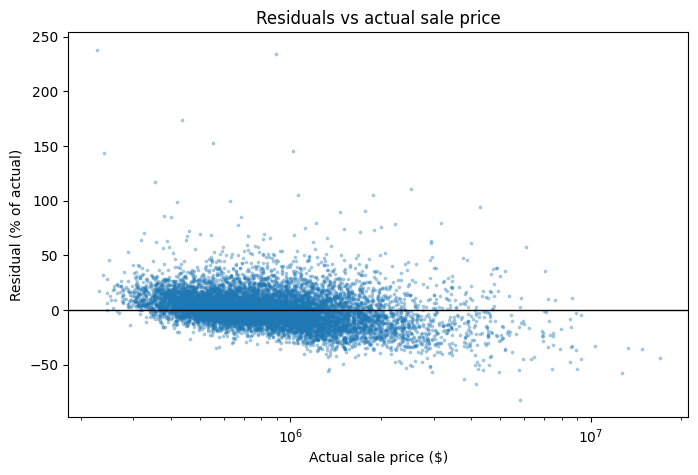

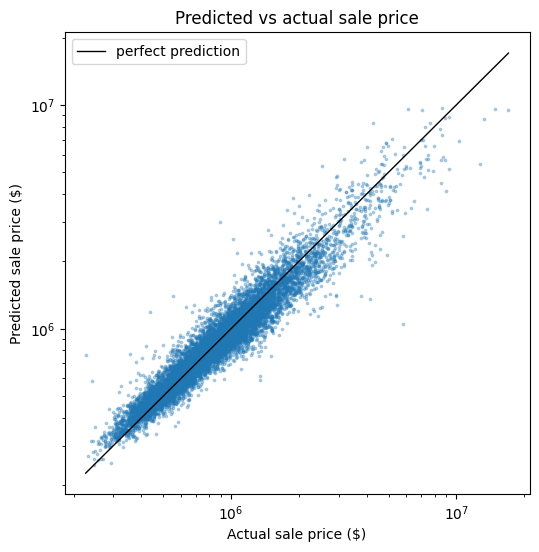

In [21]:
import diagnostics

actual = val["sold_price"]

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)

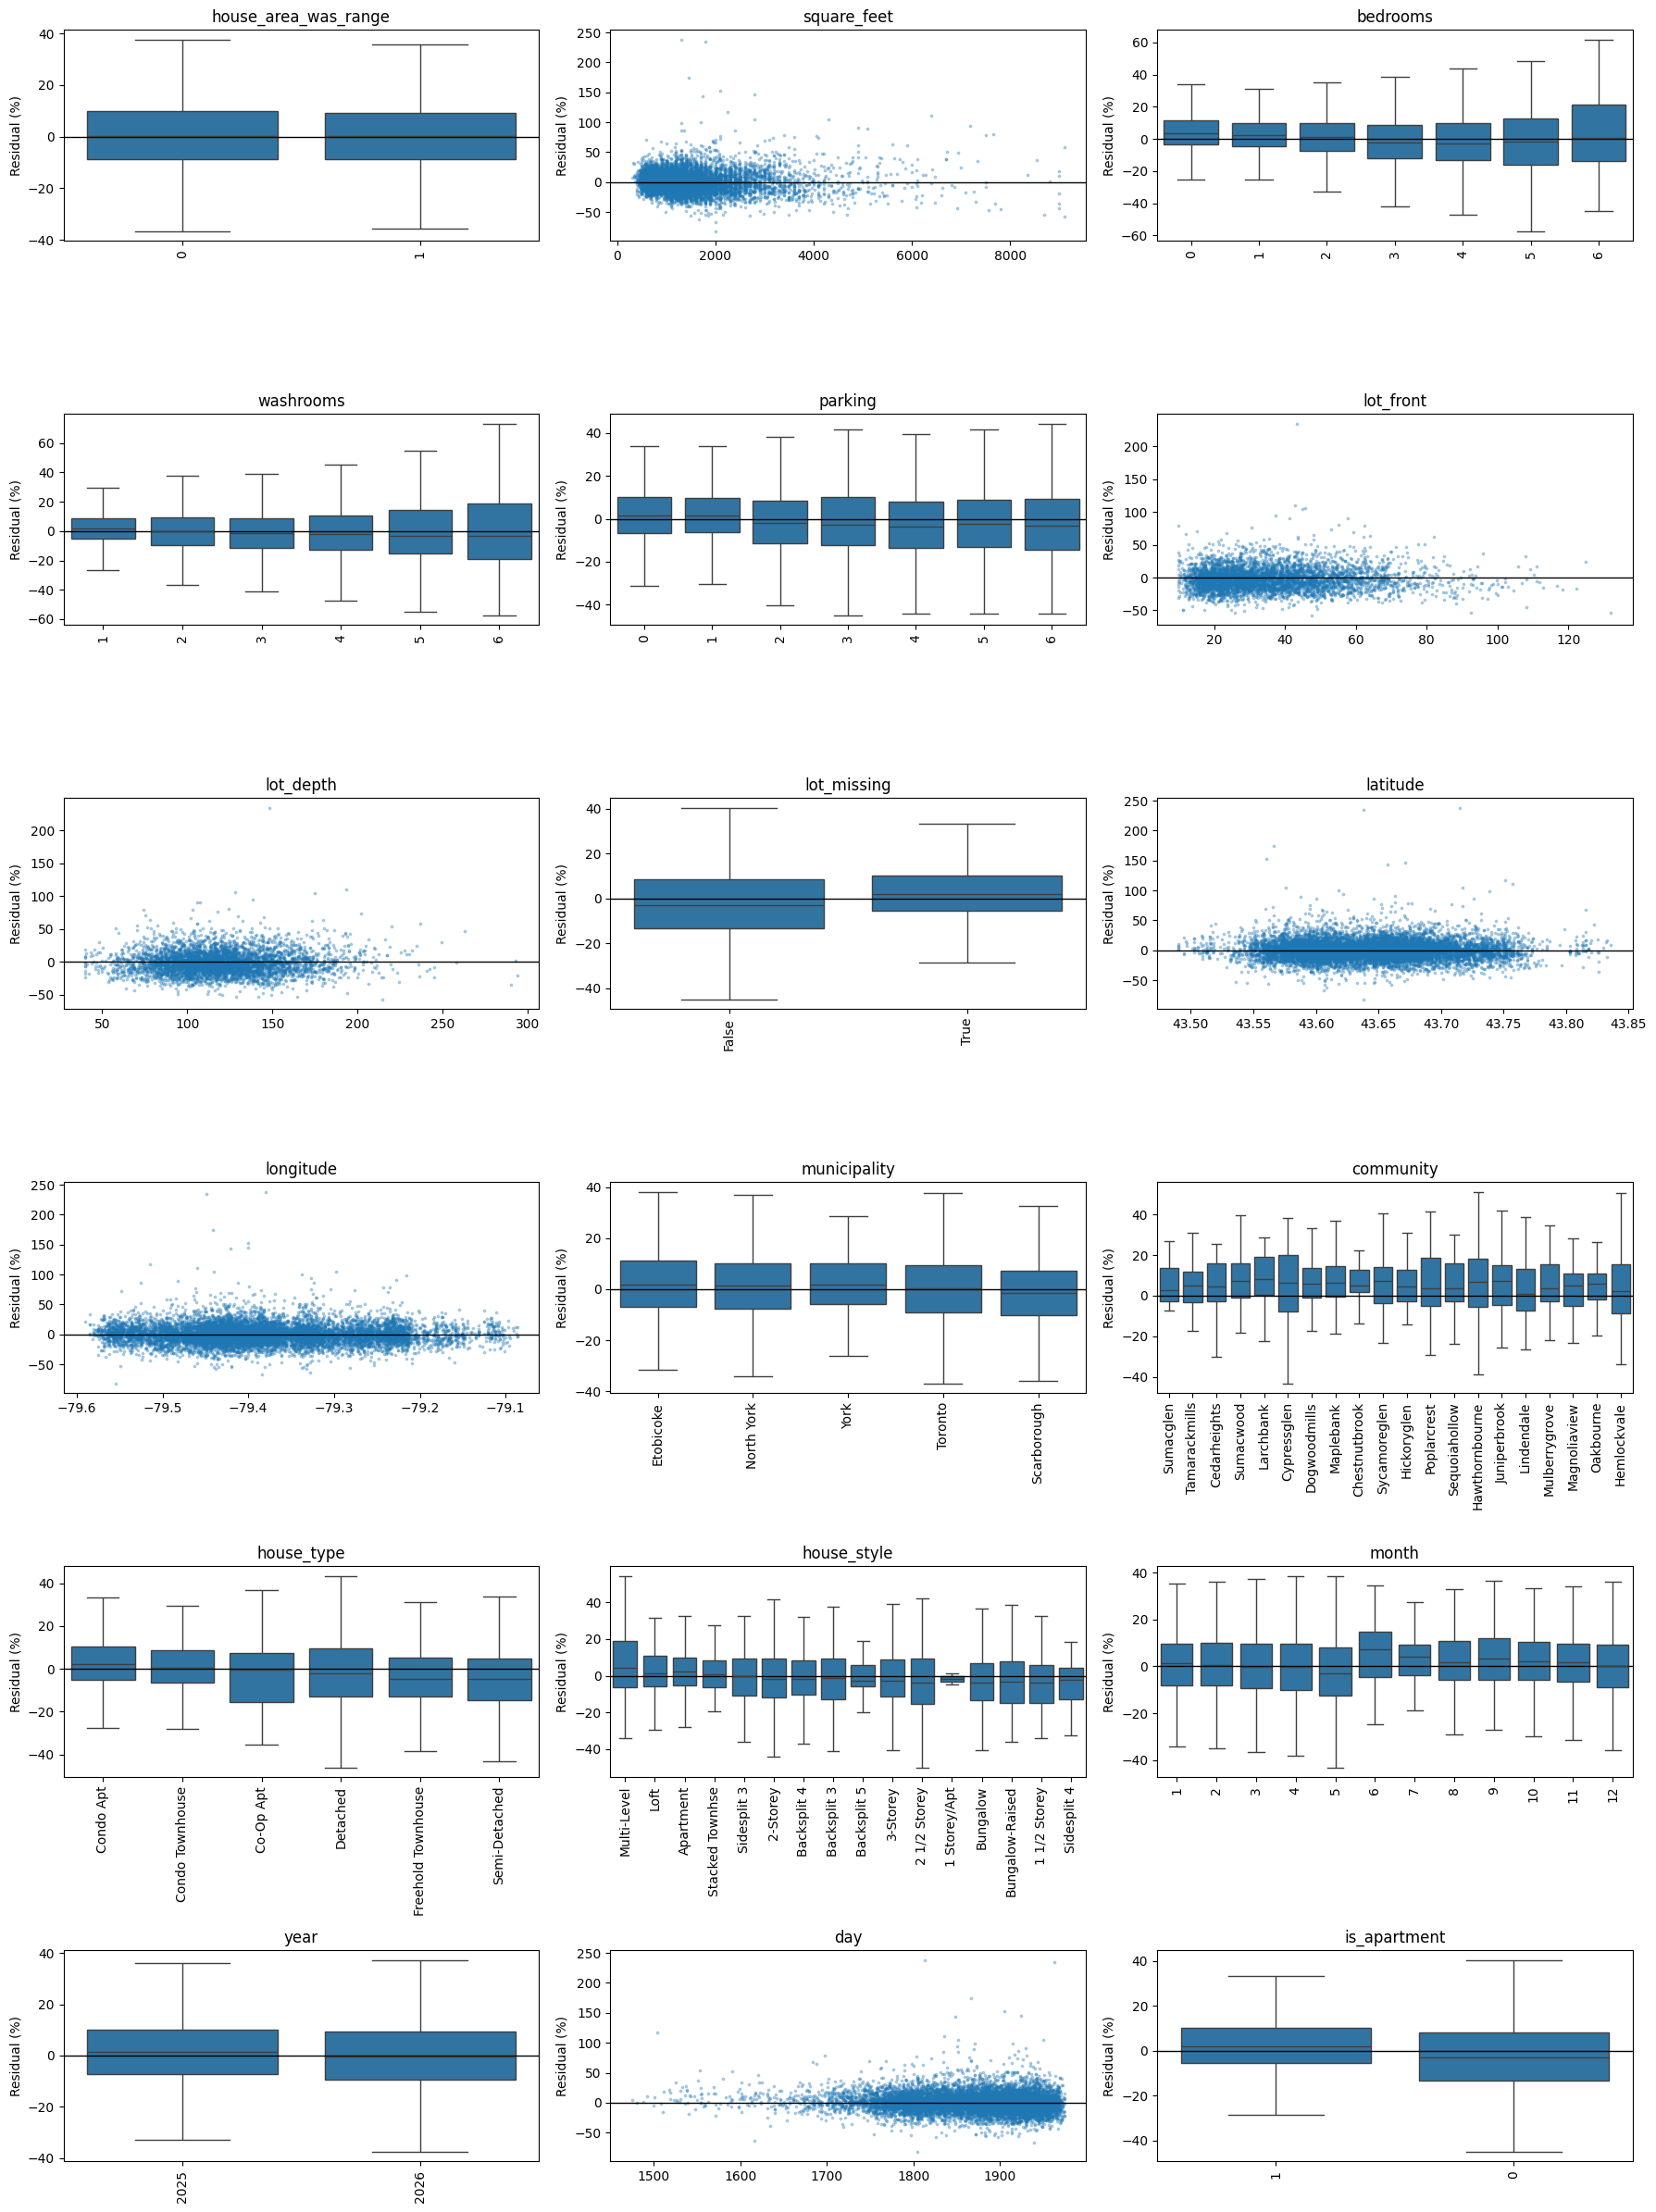

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

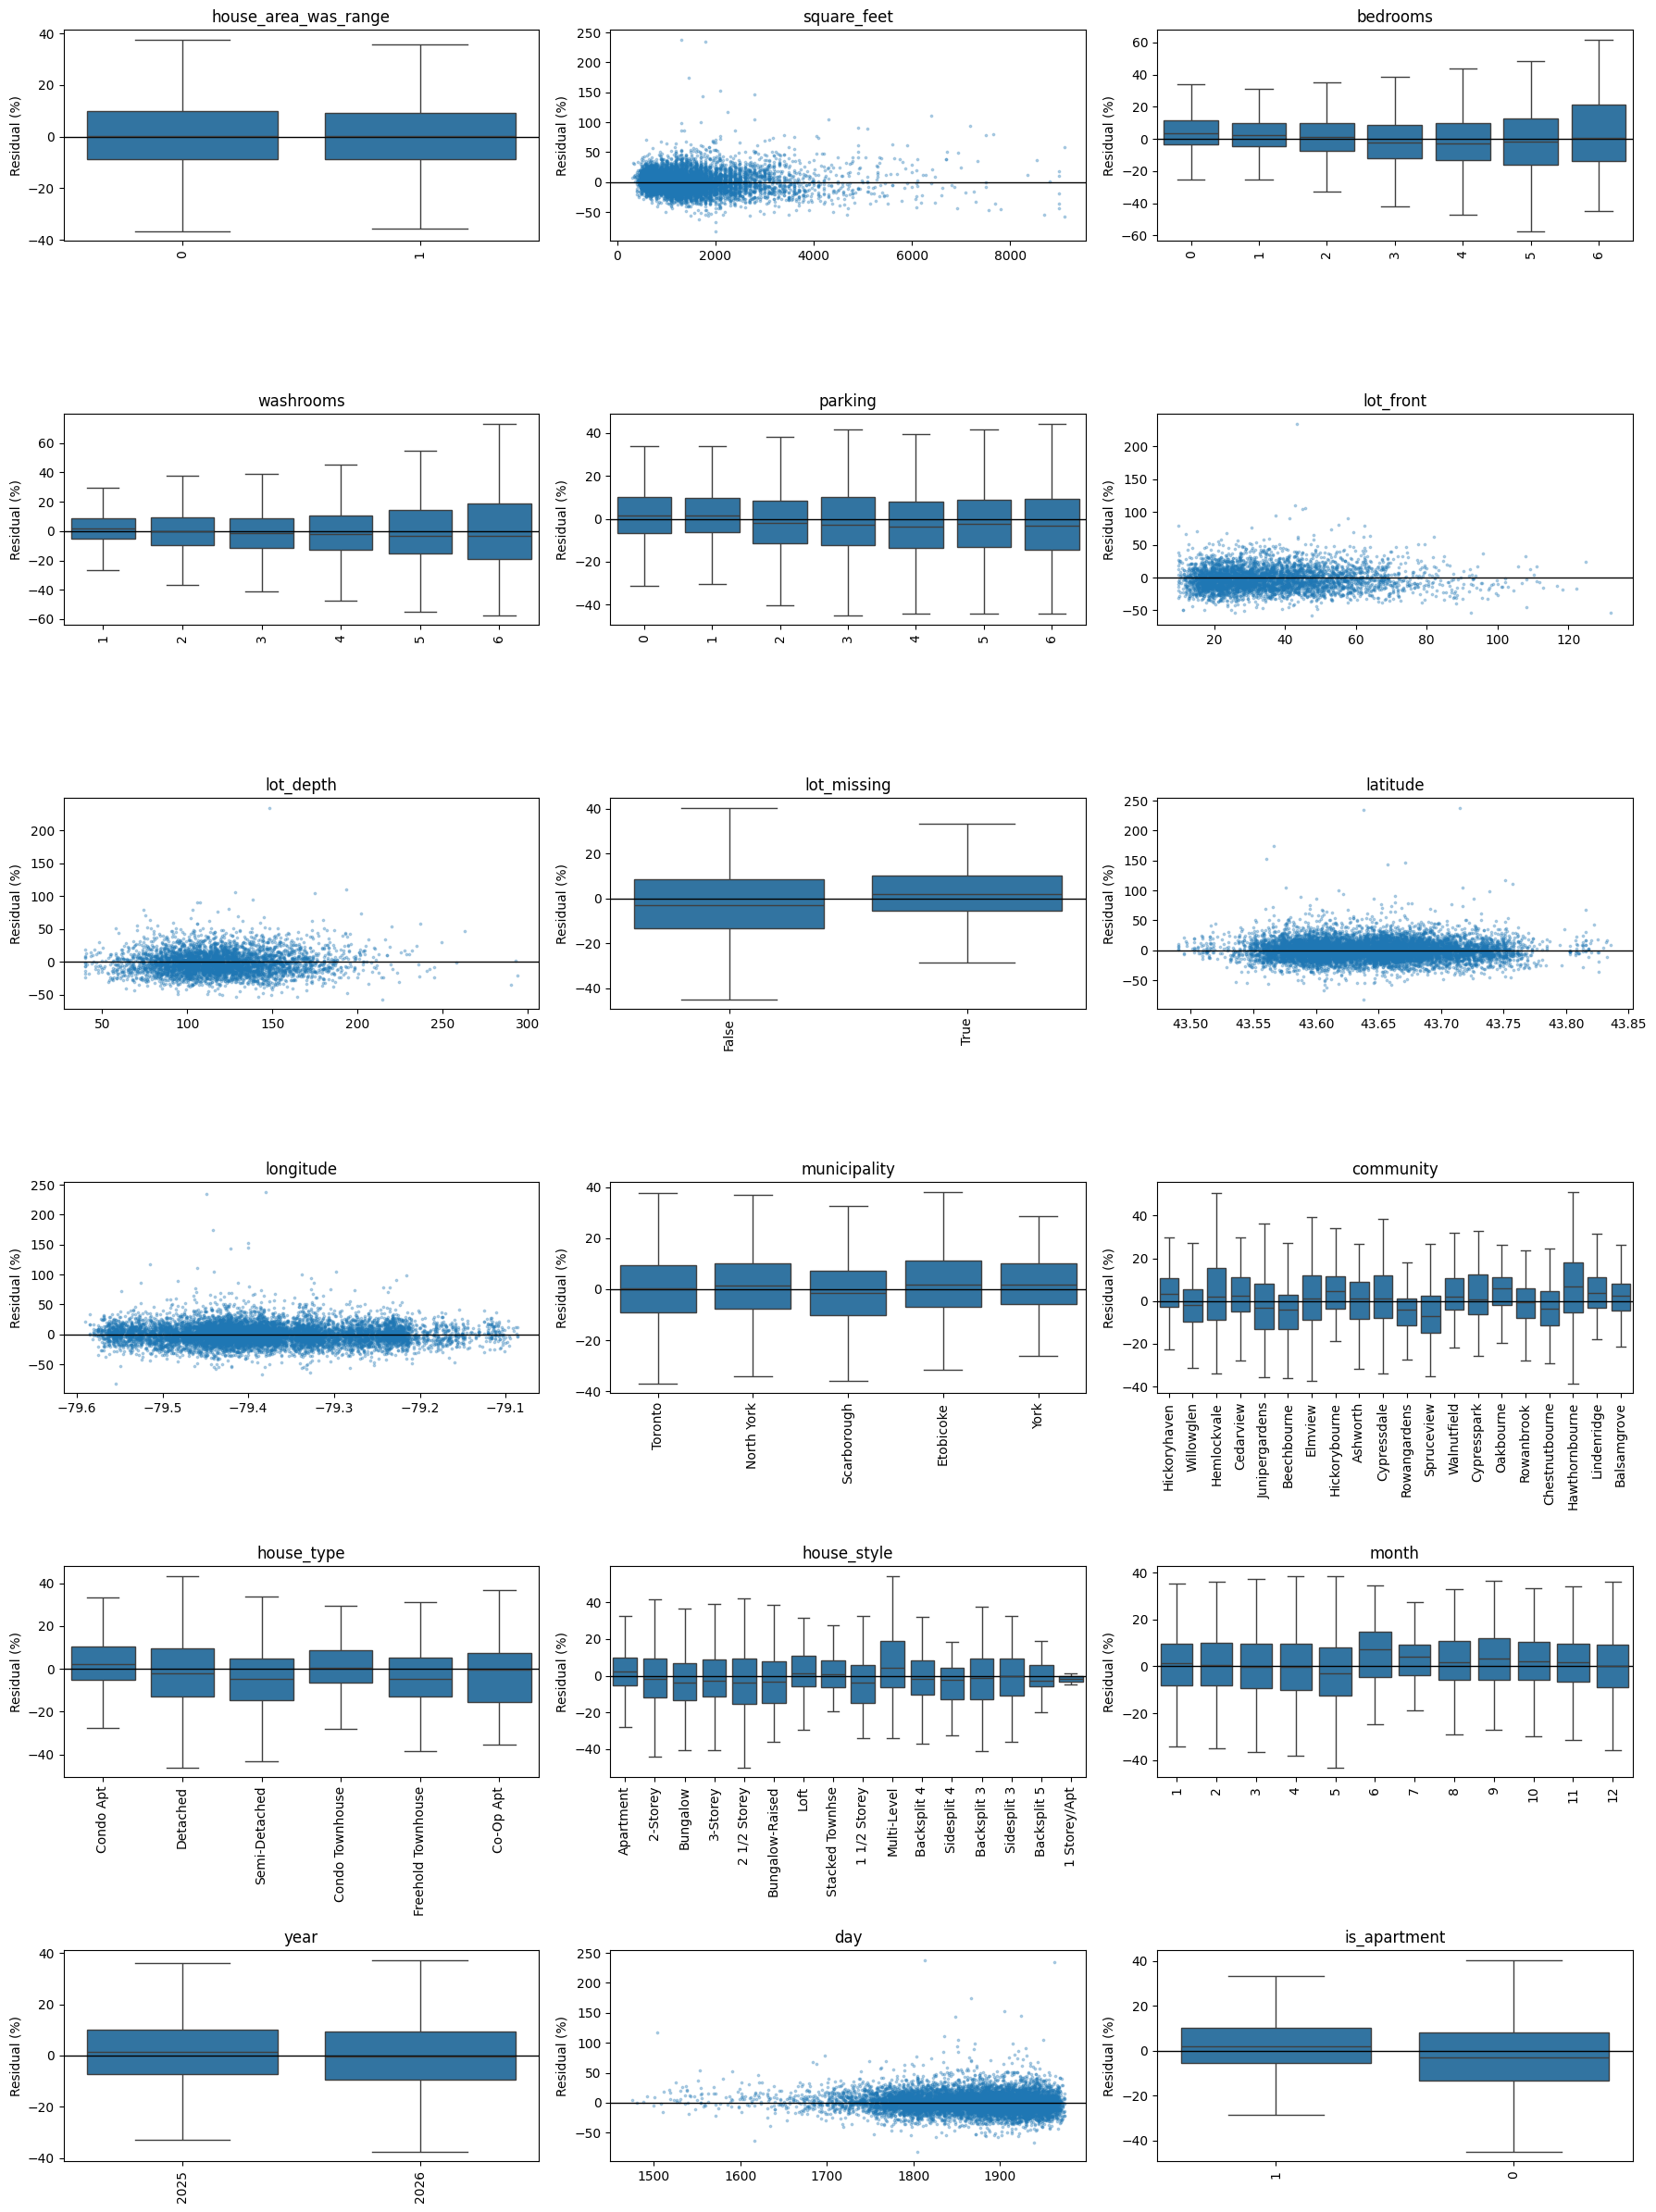

In [23]:
diagnostics.plot_residuals_by_feature(X_val, actual, predicted)